In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA

C:\Users\wasim\anaconda3\Lib\site-packages\pandas\core\computation\expressions.py:23: UserWarning: Pandas requires version '2.10.2' or newer of 'numexpr' (version '2.10.1' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED


In [2]:
df = pd.read_csv("C:\\Users\\wasim\\Downloads\\customer_segmentation.csv")

In [3]:
df.head()

,Customer_ID,Age,Annual_Income,Spending_Score,Purchase_Frequency,Average_Order_Value,Website_Visits,Discount_Usage,Customer_Tenure_Months
0,CUST0001,56,137121,63,6,229.72,27,51,35
1,CUST0002,46,95505,54,1,179.46,36,35,6
2,CUST0003,32,20869,18,1,50.39,8,49,68
3,CUST0004,60,68108,21,1,109.00,17,62,18
4,CUST0005,25,130296,45,7,149.98,32,47,29


In [4]:
df.shape

(300, 9)

In [5]:
df.columns


Index(['Customer_ID', 'Age', 'Annual_Income', 'Spending_Score',
       'Purchase_Frequency', 'Average_Order_Value', 'Website_Visits',
       'Discount_Usage', 'Customer_Tenure_Months'],
      dtype='str')

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 300 entries, 0 to 299
Data columns (total 9 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Customer_ID             300 non-null    str    
 1   Age                     300 non-null    int64  
 2   Annual_Income           300 non-null    int64  
 3   Spending_Score          300 non-null    int64  
 4   Purchase_Frequency      300 non-null    int64  
 5   Average_Order_Value     300 non-null    float64
 6   Website_Visits          300 non-null    int64  
 7   Discount_Usage          300 non-null    int64  
 8   Customer_Tenure_Months  300 non-null    int64  
dtypes: float64(1), int64(7), str(1)
memory usage: 23.6 KB


In [7]:
df.isnull().sum()

Customer_ID               0
Age                       0
Annual_Income             0
Spending_Score            0
Purchase_Frequency        0
Average_Order_Value       0
Website_Visits            0
Discount_Usage            0
Customer_Tenure_Months    0
dtype: int64

In [8]:
df.duplicated().sum()

np.int64(0)

In [9]:
df.describe()

,Age,Annual_Income,Spending_Score,Purchase_Frequency,Average_Order_Value,Website_Visits,Discount_Usage,Customer_Tenure_Months
count,300.000000,300.000000,300.000000,300.000000,300.00000,300.000000,300.000000,300.000000
mean,41.326667,83618.020000,52.160000,4.013333,146.05250,28.330000,46.366667,35.723333
std,13.887506,39069.061264,21.752201,1.789926,57.76682,12.040668,14.915107,20.111897
min,18.000000,19062.000000,1.000000,1.000000,20.00000,1.000000,1.000000,1.000000
25%,29.000000,46284.000000,37.000000,3.000000,101.27750,20.000000,36.000000,18.000000
50%,42.000000,86417.500000,52.000000,4.000000,150.38500,28.000000,47.000000,34.500000
75%,53.000000,118272.750000,67.000000,5.000000,189.58250,36.000000,58.000000,53.000000
max,65.000000,149800.000000,100.000000,8.000000,278.00000,62.000000,70.000000,72.000000


In [10]:
X = df.drop(['Customer_ID', 'Cluster', 'Segment'], axis=1, errors='ignore')

In [11]:
X.head()

,Age,Annual_Income,Spending_Score,Purchase_Frequency,Average_Order_Value,Website_Visits,Discount_Usage,Customer_Tenure_Months
0,56,137121,63,6,229.72,27,51,35
1,46,95505,54,1,179.46,36,35,6
2,32,20869,18,1,50.39,8,49,68
3,60,68108,21,1,109.00,17,62,18
4,25,130296,45,7,149.98,32,47,29


In [12]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

In [13]:
inertia = []

for k in range(2, 11):
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    kmeans.fit(X_scaled)
    inertia.append(kmeans.inertia_)

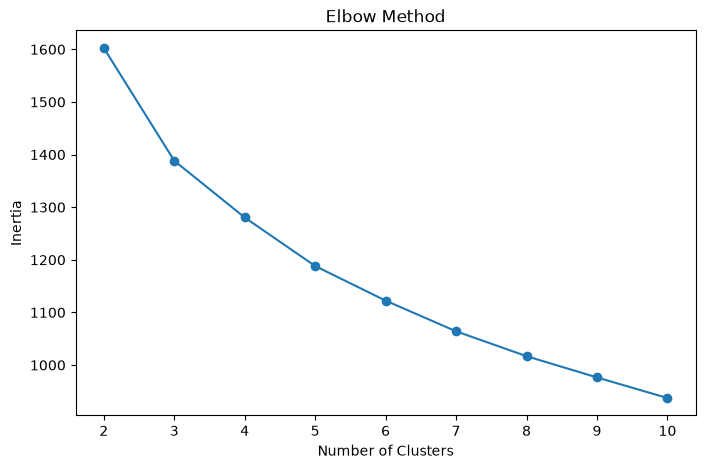

In [14]:
plt.figure(figsize=(8, 5))
plt.plot(
    range(2, 11),
    inertia,
    marker='o'
)
plt.xlabel("Number of Clusters")
plt.ylabel("Inertia")
plt.title("Elbow Method")
plt.show()

In [15]:
kmeans = KMeans(
        n_clusters=4,
        random_state=42,
        n_init=10 
)
cluster = kmeans.fit_predict(X_scaled)

In [16]:
df['Cluster'] = cluster

In [17]:
df.head()

,Customer_ID,Age,Annual_Income,Spending_Score,Purchase_Frequency,Average_Order_Value,Website_Visits,Discount_Usage,Customer_Tenure_Months,Cluster
0,CUST0001,56,137121,63,6,229.72,27,51,35,2
1,CUST0002,46,95505,54,1,179.46,36,35,6,0
2,CUST0003,32,20869,18,1,50.39,8,49,68,1
3,CUST0004,60,68108,21,1,109.00,17,62,18,1
4,CUST0005,25,130296,45,7,149.98,32,47,29,0


In [18]:
df['Cluster'].value_counts().sort_index()

Cluster
0    69
1    93
2    74
3    64
Name: count, dtype: int64

In [19]:
cluster_summary = df.groupby('Cluster').mean(numeric_only=True)
cluster_summary

,Age,Annual_Income,Spending_Score,Purchase_Frequency,Average_Order_Value,Website_Visits,Discount_Usage,Customer_Tenure_Months
Cluster,,,,,,,,
0,26.797101,108673.304348,55.521739,4.202899,174.920290,28.115942,47.724638,36.014493
1,43.505376,42741.602151,29.731183,2.666667,85.604946,17.591398,57.430108,30.526882
2,47.608108,120669.486486,77.418919,5.581081,203.667297,40.405405,32.986486,29.689189
3,46.562500,73163.078125,51.921875,3.953125,136.150156,30.203125,44.296875,49.937500


In [20]:
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

In [21]:
print(X_pca.shape)

(300, 2)


In [22]:
clusters = df['Cluster'].values
print(len(clusters))

300


In [23]:
pca_df = pd.DataFrame(
    X_pca,
    columns=['PC1', 'PC2']
)
pca_df['Cluster'] = clusters
pca_df.head()

,PC1,PC2,Cluster
0,1.682223,0.344615,2
1,0.328905,0.848977,0
2,-3.474374,-1.177093,1
3,-2.482167,1.116558,1
4,1.085355,-0.840502,0


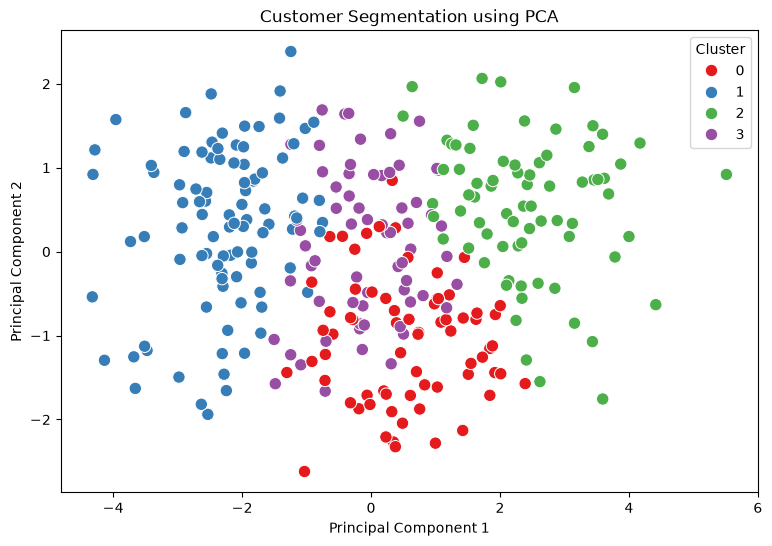

In [24]:
plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=pca_df,
    x='PC1',
    y='PC2',
    hue='Cluster',
    palette='Set1',
    s=80
)

plt.title("Customer Segmentation using PCA")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")

plt.show()

In [25]:
print(
    "PC1 Variance:",
    pca.explained_variance_ratio_[0]
)
print(
    "PC2 Variance:",
    pca.explained_variance_ratio_[1]
)
print(
    "Total Variance:",
    pca.explained_variance_ratio_.sum()
)

PC1 Variance: 0.4798518877965843
PC2 Variance: 0.13664977218053392
Total Variance: 0.6165016599771183


In [26]:
profile = df.groupby('Cluster').agg({
    'Age': 'mean',
    'Annual_Income': 'mean',
    'Spending_Score': 'mean',
    'Purchase_Frequency': 'mean',
    'Average_Order_Value': 'mean',
    'Website_Visits': 'mean',
    'Discount_Usage': 'mean',
    'Customer_Tenure_Months': 'mean'
}).round(2)
profile

,Age,Annual_Income,Spending_Score,Purchase_Frequency,Average_Order_Value,Website_Visits,Discount_Usage,Customer_Tenure_Months
Cluster,,,,,,,,
0,26.80,108673.30,55.52,4.20,174.92,28.12,47.72,36.01
1,43.51,42741.60,29.73,2.67,85.60,17.59,57.43,30.53
2,47.61,120669.49,77.42,5.58,203.67,40.41,32.99,29.69
3,46.56,73163.08,51.92,3.95,136.15,30.20,44.30,49.94


In [27]:
cluster_names = {
    0: 'Young High-Income',
    1: 'Price-Sensitive',
    2: 'VIP Premium',
    3: 'Regular Customers'
}
df['Segment'] = df['Cluster'].map(cluster_names)
display(df[['Customer_ID', 'Cluster', 'Segment']].head(20))

,Customer_ID,Cluster,Segment
0,CUST0001,2,VIP Premium
1,CUST0002,0,Young High-Income
2,CUST0003,1,Price-Sensitive
3,CUST0004,1,Price-Sensitive
4,CUST0005,0,Young High-Income
5,CUST0006,0,Young High-Income
6,CUST0007,3,Regular Customers
7,CUST0008,1,Price-Sensitive
8,CUST0009,1,Price-Sensitive
9,CUST0010,0,Young High-Income


In [28]:
df[['Customer_ID', 'Cluster', 'Segment']].head(20)

,Customer_ID,Cluster,Segment
0,CUST0001,2,VIP Premium
1,CUST0002,0,Young High-Income
2,CUST0003,1,Price-Sensitive
3,CUST0004,1,Price-Sensitive
4,CUST0005,0,Young High-Income
5,CUST0006,0,Young High-Income
6,CUST0007,3,Regular Customers
7,CUST0008,1,Price-Sensitive
8,CUST0009,1,Price-Sensitive
9,CUST0010,0,Young High-Income


In [29]:
df['Segment'].value_counts()

Segment
Price-Sensitive      93
VIP Premium          74
Young High-Income    69
Regular Customers    64
Name: count, dtype: int64

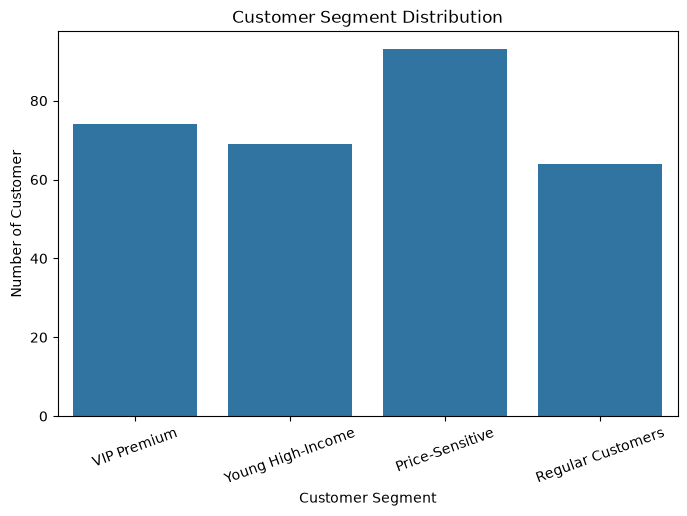

In [30]:
plt.figure(figsize=(8, 5))
sns.countplot(
    data=df,
    x='Segment'
)
plt.title("Customer Segment Distribution")
plt.xlabel("Customer Segment")
plt.ylabel("Number of Customer")
plt.xticks(rotation=20)
plt.show()

## to save data set csv file


In [31]:
df.to_csv(
    "customer_segmentation_result.csv",
    index=False
)

In [32]:
import joblib
joblib.dump(
    kmeans,
    "customer_segmentation_kmeans.pk1"
)

['customer_segmentation_kmeans.pk1']

In [33]:
joblib.dump(
    pca,
    "customer_segmentation_pca.pl1"
)

['customer_segmentation_pca.pl1']

In [34]:
df.head()

,Customer_ID,Age,Annual_Income,Spending_Score,Purchase_Frequency,Average_Order_Value,Website_Visits,Discount_Usage,Customer_Tenure_Months,Cluster,Segment
0,CUST0001,56,137121,63,6,229.72,27,51,35,2,VIP Premium
1,CUST0002,46,95505,54,1,179.46,36,35,6,0,Young High-Income
2,CUST0003,32,20869,18,1,50.39,8,49,68,1,Price-Sensitive
3,CUST0004,60,68108,21,1,109.00,17,62,18,1,Price-Sensitive
4,CUST0005,25,130296,45,7,149.98,32,47,29,0,Young High-Income


## customer value analysis

In [35]:
df["Estimated_Customer_Value"] = (
    df["Average_Order_Value"] *
    df["Purchase_Frequency"]
)
customer_value = df.groupby("Segment").agg(
    Total_Customers=("Customer_ID", "count"),
   Average_Customer_Value=("Estimated_Customer_Value", "mean"),
      Total_Estimated_Value=("Estimated_Customer_Value", "sum")
).round(2)
display(customer_value.sort_values(
    by="Average_Customer_Value",
    ascending=False
))

,Total_Customers,Average_Customer_Value,Total_Estimated_Value
Segment,,,
VIP Premium,74,1137.38,84166.45
Young High-Income,69,731.20,50452.76
Regular Customers,64,537.72,34413.80
Price-Sensitive,93,223.50,20785.86


## income and spending Behavior

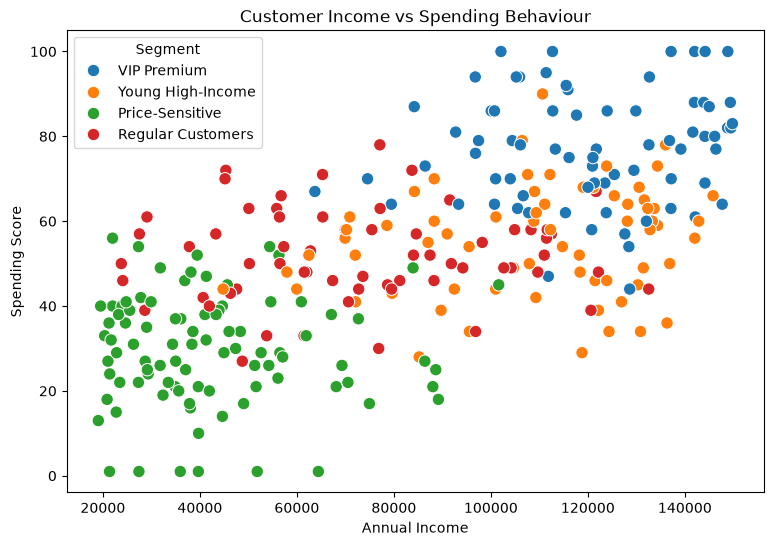

In [36]:
plt.figure(figsize=(9, 6))
sns.scatterplot(
    data=df,
    x="Annual_Income",
    y="Spending_Score",
    hue="Segment",
    s=80
)
plt.title("Customer Income vs Spending Behaviour")
plt.xlabel("Annual Income")
plt.ylabel("Spending Score")
plt.show()

## discount dependancy

In [37]:
discount_analysis = df.groupby("Segment").agg(
    Average_Discount_Usage=("Discount_Usage", "mean"),
    Average_Order_Value=("Average_Order_Value", "mean"),
    Purchase_Frequency=("Purchase_Frequency", "mean")
).round(2)
display(discount_analysis)

,Average_Discount_Usage,Average_Order_Value,Purchase_Frequency
Segment,,,
Price-Sensitive,57.43,85.60,2.67
Regular Customers,44.30,136.15,3.95
VIP Premium,32.99,203.67,5.58
Young High-Income,47.72,174.92,4.20


## website engagement

In [38]:
engagement = df.groupby("Segment").agg(
    Average_Website_Visits=("Website_Visits", "mean"),
    Average_Spending=("Spending_Score", "mean"),
    Average_Purchases=("Purchase_Frequency", "mean")
).round(2)
display(engagement)

,Average_Website_Visits,Average_Spending,Average_Purchases
Segment,,,
Price-Sensitive,17.59,29.73,2.67
Regular Customers,30.20,51.92,3.95
VIP Premium,40.41,77.42,5.58
Young High-Income,28.12,55.52,4.20


## identify high-value customers

In [39]:
high_value = df[
(df["Spending_Score"] >= 70) &
(df["Average_Order_Value"] >= 180)
].copy()
print("High Value Customers:", len(high_value))
display(
    high_value[
    ["Customer_ID", "Segment",
    "Annual_Income", "Spending_Score",
    "Average_Order_Value"]
    ].head(20)
)

High Value Customers: 47


,Customer_ID,Segment,Annual_Income,Spending_Score,Average_Order_Value
5,CUST0006,Young High-Income,112179,71,184.64
11,CUST0012,VIP Premium,146391,77,197.61
12,CUST0013,VIP Premium,104416,79,207.70
23,CUST0024,VIP Premium,115888,91,217.64
24,CUST0025,VIP Premium,125455,71,213.11
27,CUST0028,VIP Premium,120946,73,191.91
29,CUST0030,VIP Premium,123983,86,238.49
39,CUST0040,VIP Premium,149373,88,185.31
41,CUST0042,VIP Premium,142019,100,246.40
45,CUST0046,Young High-Income,136015,78,245.58


In [40]:
cluster_names = {
    0: 'Young High-Income',
    1: 'Price-Sensitive',
    2: 'VIP Premium',
    3: 'Regular Customers',
}
df["Segment"] = df["Cluster"].map(cluster_names)
display(df[["Customer_ID", "Cluster", "Segment"]].head(20))

,Customer_ID,Cluster,Segment
0,CUST0001,2,VIP Premium
1,CUST0002,0,Young High-Income
2,CUST0003,1,Price-Sensitive
3,CUST0004,1,Price-Sensitive
4,CUST0005,0,Young High-Income
5,CUST0006,0,Young High-Income
6,CUST0007,3,Regular Customers
7,CUST0008,1,Price-Sensitive
8,CUST0009,1,Price-Sensitive
9,CUST0010,0,Young High-Income
